# Exploración de datos y definición de estados


## 1. Carga de datos

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

RUTA_LOCAL = "../data/raw/telco_churn.csv"
URL_IBM = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"

df = pd.read_csv(RUTA_LOCAL if os.path.exists(RUTA_LOCAL) else URL_IBM)
print("Dimensiones:", df.shape)
df.head()

Dimensiones: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 2. Limpieza
`TotalCharges` está como texto porque hay cedas vacías, esas filas corresponden a los clientes que tienen `ternure=0` porque son recién llegados, por lo que aún no tienen ningún cobro, por lo que no aporta información de transición, por lo que las excluimos.


In [3]:
print("TotalCharges vacíos:", (df["TotalCharges"].str.strip() == "").sum())
print("Clientes con tenure = 0:", (df["tenure"] == 0).sum())

df = df[df["tenure"] > 0].copy()
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"])
df["churn"] = (df["Churn"] == "Yes").astype(int)

print("Clientes después de limpiar:", len(df))
print("Tasa global de cancelación:", round(df["churn"].mean(), 3))

TotalCharges vacíos: 11
Clientes con tenure = 0: 11
Clientes después de limpiar: 7032
Tasa global de cancelación: 0.266


## 3. ¿Qué tanto influyen el contrato y la antigüedad en la cancelación?

In [4]:
# Tasa de cancelación por tipo de contrato
por_contrato = df.groupby("Contract")["churn"].agg(tasa="mean", clientes="count").round(3)
por_contrato

,tasa,clientes
Contract,,
Month-to-month,0.427,3875
One year,0.113,1472
Two year,0.028,1685


In [5]:
# Etapas de vida del cliente según su antigüedad (meses)
cortes = [0, 12, 24, 48, 72]
etiquetas = ["E1: 1-12", "E2: 13-24", "E3: 25-48", "E4: 49-72"]
df["etapa"] = pd.cut(df["tenure"], bins=cortes, labels=etiquetas)

por_etapa = df.groupby("etapa", observed=True)["churn"].agg(tasa="mean", clientes="count").round(3)
por_etapa

,tasa,clientes
etapa,,
E1: 1-12,0.477,2175
E2: 13-24,0.287,1024
E3: 25-48,0.204,1594
E4: 49-72,0.095,2239


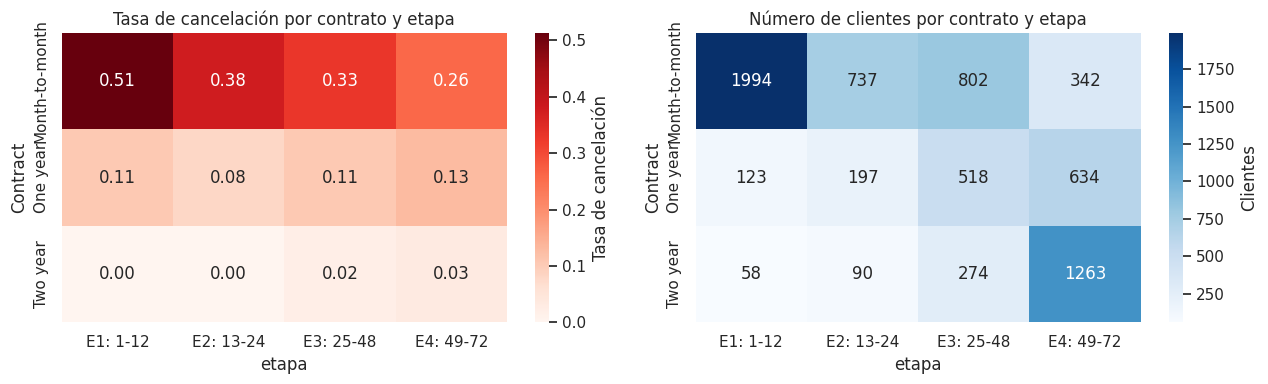

In [6]:
# Tasa de cancelación por contrato x etapa
tabla_tasa = df.pivot_table(index="Contract", columns="etapa", values="churn", aggfunc="mean", observed=True)
tabla_n = df.pivot_table(index="Contract", columns="etapa", values="churn", aggfunc="count", observed=True)

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.heatmap(tabla_tasa, annot=True, fmt=".2f", cmap="Reds", ax=ax[0], cbar_kws={"label": "Tasa de cancelación"})
ax[0].set_title("Tasa de cancelación por contrato y etapa")
sns.heatmap(tabla_n, annot=True, fmt="d", cmap="Blues", ax=ax[1], cbar_kws={"label": "Clientes"})
ax[1].set_title("Número de clientes por contrato y etapa")
plt.tight_layout()
plt.show()

El grupo más crítico es *Month-to-month* en sus primeros 12 meses más de la mitad cancela, en cambio los clientes cuyo contrato dura dos años, casi no cancelan. Esto justifica estimar una matriz de transición distinta por el tipo de contratación.

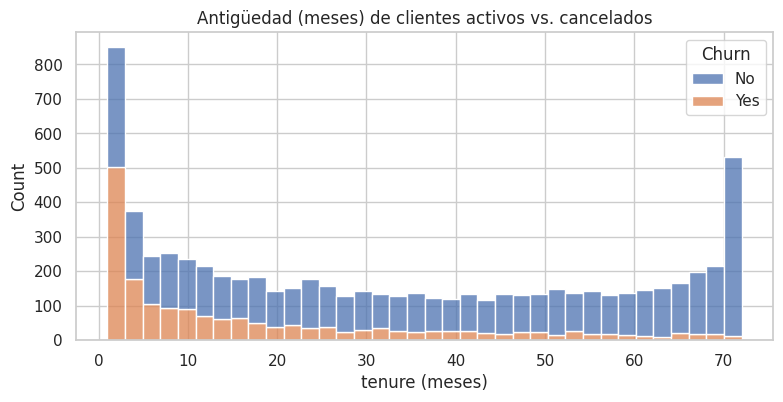

In [7]:
# Distribución de la antigüedad según si el cliente canceló o sigue activo
plt.figure(figsize=(9, 4))
sns.histplot(data=df, x="tenure", hue="Churn", bins=36, multiple="stack")
plt.title("Antigüedad (meses) de clientes activos vs. cancelados")
plt.xlabel("tenure (meses)")
plt.show()

## 4. Definición de estados de la cadena de Markov

Cada cliente se ubica en una etapa de vida, según sus metes de antigüedad, en cada mes puede permanecer en su etapa, avanzar a la siguiente o cancerlar:

| Estado | Significado | Tipo |
|---|---|---|
| **E1** | 1–12 meses | transitorio |
| **E2** | 13–24 meses | transitorio |
| **E3** | 25–48 meses | transitorio |
| **E4** | 49–72 meses (cliente maduro) | transitorio |
| **E5** | Cancelado | **absorbente** |


Entonces como nota: el data set es una foto fija, no es un historial mes a mes, por lo que los clientes activos son datos censurados, sabemos que siguen vivos hasta su ternure, pero no cuándo cancelaran, por lo que para estimar esas probabilidades podemos usar meses en riesgo en lugar de siemples porcentajes, igual que en análisis de supervivencia.


In [8]:
# Asignamos el estado de cada cliente: etapa si sigue activo, E5 si canceló
df["estado_actual"] = np.where(df["churn"] == 1, "E5: Cancelado", df["etapa"].astype(str))

# Tipo de contrato simplificado, que usaremos para segmentar
df["contrato"] = df["Contract"].map({"Month-to-month": "Mensual", "One year": "1 año", "Two year": "2 años"})

df["estado_actual"].value_counts()

,count
estado_actual,
E4: 49-72,2026
E5: Cancelado,1869
E3: 25-48,1269
E1: 1-12,1138
E2: 13-24,730


In [9]:
# Etapa en la que estaba el cliente al momento de cancelar (clave para estimar la matriz de transición)
cancelados = df[df["churn"] == 1]
print("Cancelaciones por etapa y contrato:")
cancelados.pivot_table(index="contrato", columns="etapa", values="churn", aggfunc="count", observed=True).fillna(0).astype(int)

Cancelaciones por etapa y contrato:


etapa,E1: 1-12,E2: 13-24,E3: 25-48,E4: 49-72
contrato,,,,
1 año,13,16,55,82
2 años,0,0,6,42
Mensual,1024,278,264,89


## 5. Guardar datos limpios para el siguiente notebook

In [15]:
columnas = ["customerID", "contrato", "tenure", "etapa", "estado_actual", "churn", "MonthlyCharges", "TotalCharges"]

df[columnas].to_csv("telco_estados.csv", index=False)
print("Guardado en telco_estados.csv")

# En Colab: descarga el archivo a tu computadora
from google.colab import files
files.download("telco_estados.csv")

Guardado en telco_estados.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>